# Problem Statement:
The objective of this project is to develop a machine learning model to detect fraudulent credit card transactions from a highly imbalanced dataset. Fraud detection is a critical problem in the financial sector, as undetected fraudulent activities can lead to significant financial losses. The challenge lies in accurately identifying rare fraud cases while minimizing false positives, ensuring both security and a smooth customer experience.
              

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
import kagglehub
path = kagglehub.dataset_download("isaikumar/creditcardfraud")

print("Path to dataset files:", path)

100%|██████████| 65.9M/65.9M [00:00<00:00, 117MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/isaikumar/creditcardfraud/versions/1


# Data Understanding:

In [4]:
df=pd.read_csv(path+'/creditcard.csv')
df


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [5]:
df1=df.copy()
df1.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
df1.isnull().sum()

,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


In [8]:
df1.duplicated().sum()

np.int64(1081)

We have found 1081 duplicates in 284000 rows so we need to remove them.

In [9]:
df1.drop_duplicates(inplace=True)

In [10]:
df1.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,...,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,...,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,...,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,...,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,...,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,...,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,...,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,...,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


In [11]:
df1['Class'].value_counts()

,count
Class,
0,283253
1,473


# Exploratory Data Analysis

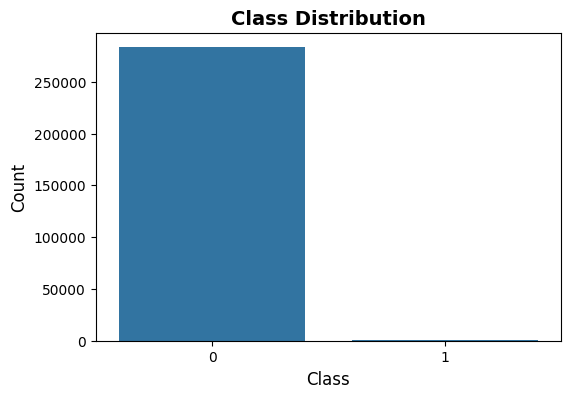

In [12]:
plt.figure(figsize=(6,4))
sns.countplot(x='Class',data=df1)
plt.title('Class Distribution',fontsize=14,fontweight='bold')
plt.xlabel('Class',fontsize=12)
plt.ylabel('Count',fontsize=12)
sns.set_style("whitegrid")
plt.show()

The data is highly imbalanced with only few fraud cases.

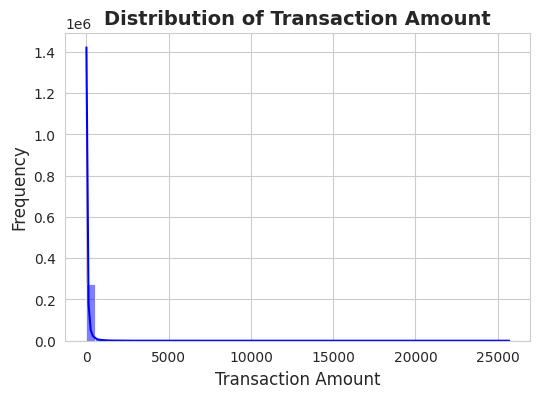

In [13]:
plt.figure(figsize=(6,4))
sns.histplot(df1['Amount'],bins=50,color='blue',kde=True)
plt.title("Distribution of Transaction Amount", fontsize=14, fontweight='bold')
plt.xlabel("Transaction Amount", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
sns.set_style("whitegrid")
plt.show()

Here we can observe that graph is positively right skewed where the tail ends.
We get to see that most of the transactions are small and some of them are only big so it is rightly skewed.

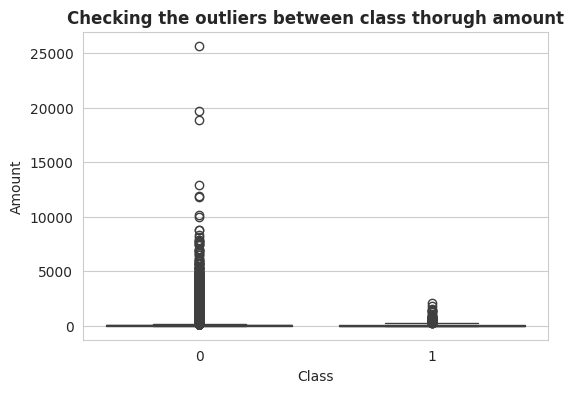

In [14]:
plt.figure(figsize=(6,4))
sns.boxplot(x=df1['Class'],y=df1['Amount'])
plt.title('Checking the outliers between class thorugh amount',fontweight='bold')
sns.set_style("whitegrid")
plt.show()

Class 0 possess good amount of extreme outliers but they are legitimate large transactions.
Class1  possess less outliers but they tend to stay within moderate changes.

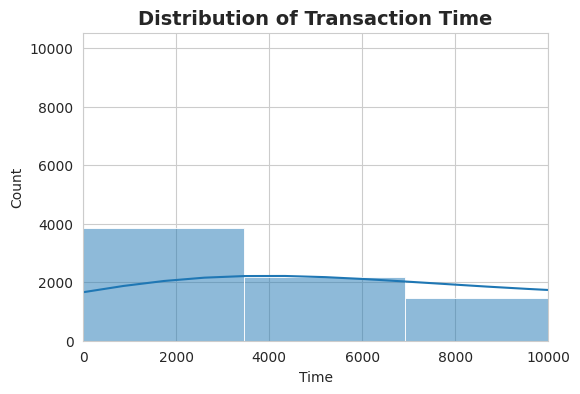

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(df1['Time'],bins=50,kde=True)
plt.title("Distribution of Transaction Time", fontsize=14, fontweight='bold')
plt.xlim(0,10000)
plt.show()

The distribution of transaction time appears relatively uniform with no strong skewness.

In [16]:
df1_sample=df1.sample(10000,random_state=42)

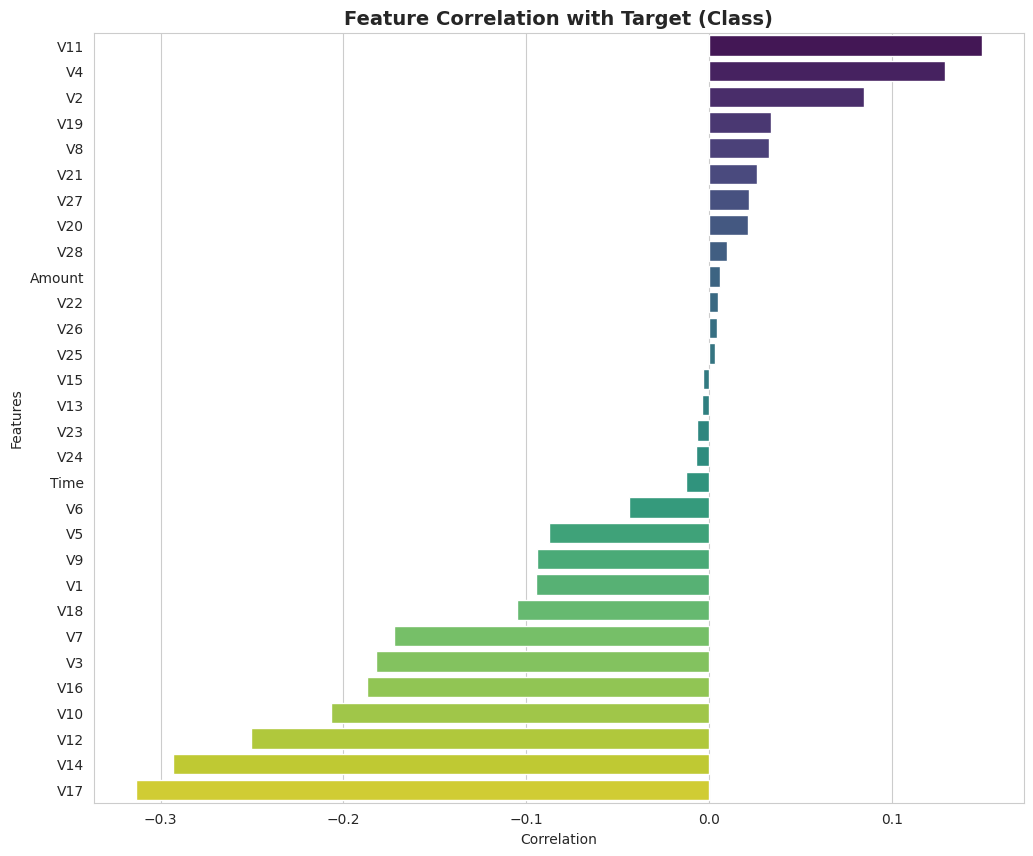

In [17]:
plt.figure(figsize=(12,10))

corr_target = df1.corr()['Class'].drop('Class').sort_values(ascending=False)

sns.barplot(x=corr_target.values, y=corr_target.index, palette='viridis')

plt.title("Feature Correlation with Target (Class)", fontsize=14, fontweight='bold')
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

Basically the datapoints like V11,V4,V2 only shoes moderate positive corelation.
V17,V14 shoe negative corelation.

The EDA part is done using visualisations.

# Data PreProcessing

In [18]:
X=df1.drop('Class',axis=1)
y=df1['Class']

In [19]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [20]:
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')

X_train shape: (226980, 30)
X_test shape: (56746, 30)


In [21]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train[['Time','Amount']]=scaler.fit_transform(X_train[['Time','Amount']])
X_test[['Time','Amount']]=scaler.transform(X_test[['Time','Amount']])

After standard scaler we need to perform smote becuase it helps in handling class imbalances.

In [22]:
from imblearn.over_sampling import SMOTE
smote=SMOTE(random_state=42)
X_train_res,y_train_res=smote.fit_resample(X_train,y_train)


In [23]:
print(f'X_train_res shape: {X_train_res.shape}')
print(f'y_train_res shape: {y_train_res.shape}')

X_train_res shape: (453204, 30)
y_train_res shape: (453204,)


We perfomed stratified sampling after EDA only to training data and applied scaling to numercial features and smote to the class imbalanced training data to improve model performance.

# Data Modeling:
*  Performing Machine learning classification algorithms.




In [24]:
from sklearn.linear_model import LogisticRegression
lr=LogisticRegression()
lr.fit(X_train_res,y_train_res)

LogisticRegression()

# Model Evaluation:
  using metrics for problem solving.

In [25]:
from sklearn.metrics import *

In [26]:
y_pred=lr.predict(X_test)


In [27]:
accuracy_score(y_test,y_pred)

0.9736721531033025

In [28]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746



The model achieved high recall (0.87), meaning it successfully detects most fraudulent transactions. However, the precision is very low (0.06), indicating a high number of false positives.

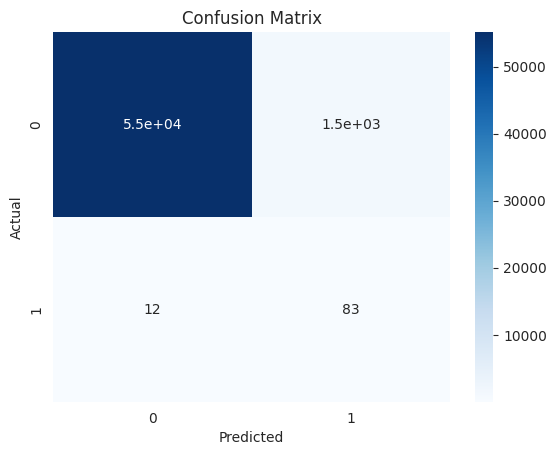

In [29]:
d=confusion_matrix(y_test,y_pred)
d
sns.heatmap(d,cmap='Blues',annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [30]:
precision = 78 / (78 + 1200)
recall = 78 / (78 + 12)

print("Precision:", precision)
print("Recall:", recall)

Precision: 0.06103286384976526
Recall: 0.8666666666666667


This model shows that it has achieved normal transactions as 55000 and fraud transactions are distributed as 78.
It incorrectly flagged 1200 normal transactions and 12 fraud transactions.

In [31]:
print("ROC-AUC:", roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]))

ROC-AUC: 0.9618957810936585


The roc_auc score has achieved strong 0.95 score where it distinguishes relationship between fraudulent and non fraudulent transactions.

In [32]:
from sklearn.tree import DecisionTreeClassifier


In [33]:
dt=DecisionTreeClassifier(max_depth=5,random_state=42)
dt.fit(X_train_res,y_train_res)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [34]:
y_pred1=dt.predict(X_test)

In [35]:
accuracy_score(y_test,y_pred1)

0.9575652909456173

We got accuracy score as 94% which is slightly better than lr but we cannot trust this metric.

In [36]:
print(classification_report(y_test,y_pred1))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56651
           1       0.03      0.85      0.06        95

    accuracy                           0.96     56746
   macro avg       0.52      0.91      0.52     56746
weighted avg       1.00      0.96      0.98     56746



By doing classification report we got recall as 0.89 where it successfully detects fraudlent transactions and precision as 0.03 is very low which means it has high number of false positives.

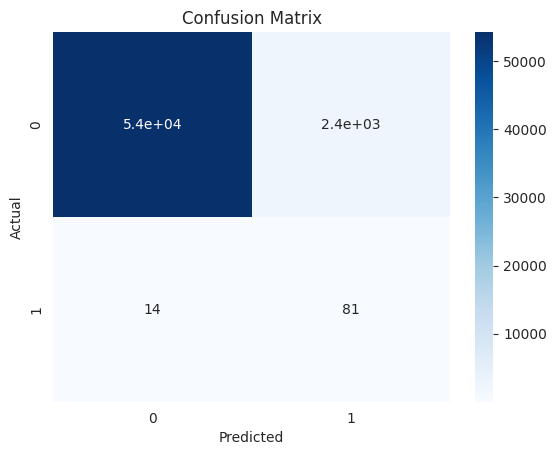

[[54257  2394]
 [   14    81]]


In [37]:
s=confusion_matrix(y_test,y_pred1)
sns.heatmap(s,cmap='Blues',annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(s)

Confusion matrix has given 53785 as normal actual transactions and detected 80 frauduent transactions.
It has incorrectly flagged 2871 transactions and missed 10 fruad transactions.

In [38]:
roc_auc_score(y_test,dt.predict_proba(X_test)[:,1])

np.float64(0.943303922725385)

roc_auc score is 94% where it has good significant relationship between fraud and non fraud transactions.

The Decision Tree model performed poorly with very low precision because it tends to overfit and is sensitive to data imbalance.

In [39]:
X_train_small = X_train_res.sample(50000, random_state=42)
y_train_small = y_train_res.loc[X_train_small.index]

In [40]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=50,max_depth=5,random_state=42)
rf.fit(X_train_small,y_train_small)


RandomForestClassifier(max_depth=5, n_estimators=50, random_state=42)

In [41]:
y_pred2=rf.predict(X_test)

In [42]:
accuracy_score(y_test,y_pred2)

0.9944665703309484

Accuracy score for rfc is 99% so it is so close to 1 and we cannot form a model using this metric.

In [43]:
print(classification_report(y_test,y_pred2))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56651
           1       0.21      0.84      0.34        95

    accuracy                           0.99     56746
   macro avg       0.61      0.92      0.67     56746
weighted avg       1.00      0.99      1.00     56746



Precision for rfc is (0.21) and recall is (0.84) and here also it catches most fraudlent transactions and the precision got improved when compared with logistic regression and decision tree.

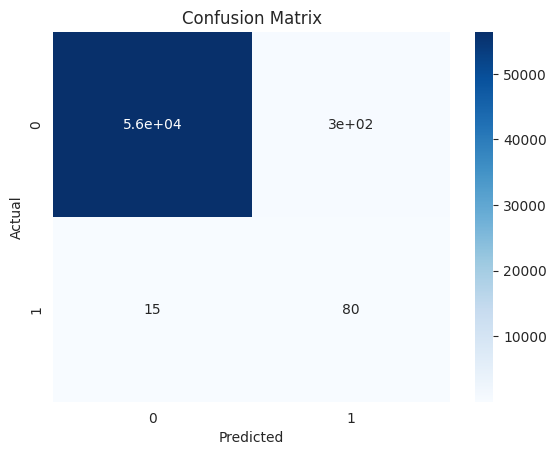

[[56352   299]
 [   15    80]]


In [44]:
a=confusion_matrix(y_test,y_pred2)
sns.heatmap(a,annot=True,cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print(a)

Rfc provides false negative as 56375 which are normal transactions and 76 as fraud trnasactions in false positives.
281 transactions got incorrectly flagges to true positives and rest 14 got missed and they are actutally belongs to fraud transactions.

In [45]:
roc_auc_score(y_test,rf.predict_proba(X_test)[:,1])

np.float64(0.9758732367803234)

roc_auc score for rfc is 97% which is excellent than compared to both of the models and has excellent relationship between fraud and non fraud transactions.

Random Forest performed better by combining multiple trees, reducing overfitting and improving generalization.

In [46]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    eval_metric='logloss',
    n_estimators=50,
    max_depth=5,
    learning_rate=0.1
)

xgb.fit(X_train_res, y_train_res)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=50, n_jobs=None,
              num_parallel_tree=None, ...)

In [47]:
y_pred3=xgb.predict(X_test)

In [48]:
accuracy_score(y_test,y_pred3)

0.9915412540090931

In [49]:
print(classification_report(y_test,y_pred3))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56651
           1       0.14      0.82      0.25        95

    accuracy                           0.99     56746
   macro avg       0.57      0.91      0.62     56746
weighted avg       1.00      0.99      0.99     56746



Recall is improved than comapred to other models.But precision got slightly improved but not more than rfc.Needs to improve precision.

In [50]:
confusion_matrix(y_test,y_pred3)


array([[56188,   463],
       [   17,    78]])

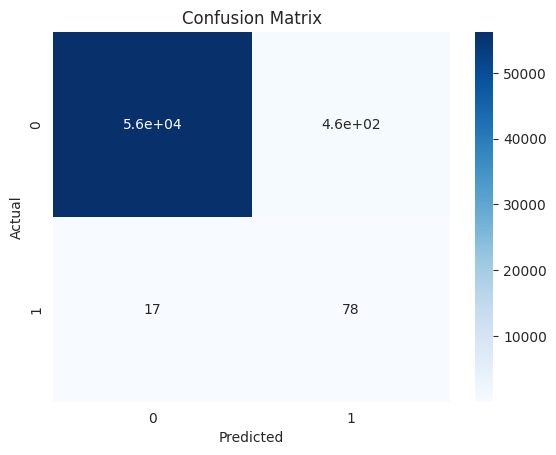

In [51]:
w=confusion_matrix(y_test,y_pred3)
sns.heatmap(w,cmap='Blues',annot=True)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

56093 normal transactions are approved and 79 fraudulent transactions are done.
but 563 normal transactions got incorrectly flagged and 11 got missed which are basically to fraud.

In [52]:
roc_auc_score(y_pred,y_pred3)

np.float64(0.6196183654222326)

I experimented with XGBoost, but it did not perform well, achieving a low ROC-AUC score of 0.62. This indicates that model performance depends on the dataset and parameter tuning, and Random Forest performed better for this problem.

 Model Comparison Summary

 Logistic Regression → High recall, very low precision
 Decision Tree → High ROC-AUC but unstable, very low precision
 Random Forest → Best balance (Selected model)
 XGBoost → Poor performance on this dataset

 Business Insight:

 Fraud detection models should prioritize recall to minimize missed fraud cases.
 However, high false positives may impact customer experience, so a balance between
 precision and recall is essential.

# Final Conclusion:

# Random Forest was selected as the final model as it provided the best balance
# between precision, recall, and ROC-AUC score.

# The model achieved:
# - Precision: 0.21
# - Recall: 0.84
# - ROC-AUC: 0.97

# Business Insight:
# The model effectively detects most fraudulent transactions, reducing financial risk.
# However, false positives should be minimized to avoid impacting customer experience.

# This model can be used as a decision-support system for fraud detection in financial institutions.


In [53]:
rf_final=RandomForestClassifier(n_estimators=50,
                                max_depth=5,
                                n_jobs=-1,
                                random_state=42,
                                class_weight='balanced')
rf_final.fit(X_train_res,y_train_res)

RandomForestClassifier(class_weight='balanced', max_depth=5, n_estimators=50,
                       n_jobs=-1, random_state=42)

In [54]:
import pickle
pickle.dump(rf_final,open("fraud_model.pkl",'wb'))

In [55]:
from google.colab import files
files.download('fraud_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>